# Setup

In [1]:
import sys

from Part_2.Notebooks.Learner import Callback
from Part_2.course22p2.miniai.datasets import show_image, inplace, DataLoaders

sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

import torch

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
import pickle, gzip, math, os, time, shutil, torch, matplotlib as mpl, numpy as np, matplotlib.pyplot as plt
import fastcore.all as fc
from collections.abc import Mapping
from pathlib import Path
from operator import attrgetter, itemgetter
from functools import partial
from copy import copy
from contextlib import contextmanager

import torchvision.transforms.functional as TF, torch.nn.functional as F
from torch import tensor, nn, optim
from torch.utils.data import DataLoader, default_collate
from torch.nn import init
from torch.optim import lr_scheduler
from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset, load_dataset_builder

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from fastcore.test import test_close

torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
torch.manual_seed(1)

import logging

logging.disable(logging.WARNING)

set_seed(42)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
xl,yl = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

bs = 1024
# we took the mean() and the std() for a whole batch and got this numbers
xmean,xstd = 0.28, 0.35

# transform + normalize
@inplace
def transformi(b): b[xl] = [(TF.to_tensor(o)-xmean)/xstd for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=4)

In [3]:
# the set of CB , leaky relu , weight initialization ,...
metrics = MetricsCB(accuracy=MulticlassAccuracy())
astats = ActivationStats(fc.risinstance(GeneralRelu))
cbs = [DeviceCB(), metrics, ProgressCB(plot=True), astats]
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
iw = partial(init_weights, leaky=0.1)
lrf_cbs = [DeviceCB(), LRFinderCB()]

#  SGD Optimizer

In [4]:
class SGD:
    def __init__(self,params,lr,wd=0.):
        params = list(params)
        fc.store_attr()
        self.i = 0

    def step(self):
        with torch.no_grad():
            for p in self.params:
                self.reg_step(p)
                self.opt_step(p)
        self.i += 1

    def reg_step(self,p):
        if self.wd  != 0 : p *= 1 - (self.lr * self.wd)
    def opt_step(self,p): p -= p.grad*self.lr
    def zero_grad(self):
        for p in self.params : p.grad.data.zero_()

    WEIGHT DECAY:   p *= (1 - lr*wd)      direct weight shrink
    L2 REG:         grad += wd*p          adds penalty to gradient
    BOTH Happen first then we make the optim.step()

    They are:
    - SAME for SGD (if we combine the (wd or l2) step with the normal
    opt_step, same result)
    - DIFFERENT for Adam → weight decay preferred

At the weight decay

    # Jeremy's markdown version:
    weight -= lr * wd * weight
    # expanded from:
    weight = weight - lr*wd*weight
    weight = weight * (1 - lr*wd)

In [5]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=0.4, cbs=cbs, opt_func=SGD)

accuracy,loss,epoch,train
0.772,0.640,0,train
0.826,0.477,0,eval
0.846,0.424,1,train
0.850,0.417,1,eval
0.865,0.371,2,train
0.846,0.416,2,eval


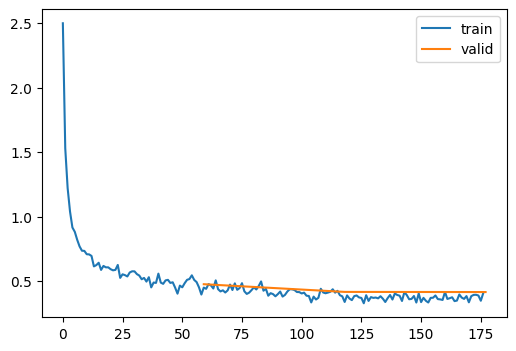

In [6]:
learn.fit(3)

# Momentum

In [7]:
class Momentum(SGD):
    def __init__(self,params,lr,wd=0.,mom=0.1):
        super().__init__(params,lr,wd)
        self.mom = mom

    def opt_step(self,p):
        if not hasattr(p,'grad_avg'): p.grad_avg = torch.zeros_like(p.grad)
        p.grad_avg = p.grad_avg.lerp_(p.grad, self.mom)
        p -= p.grad_avg * self.lr

`torch.zeros_like(p.grad)` -> same shape , all zeros

In [8]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=1.5, cbs=cbs, opt_func=Momentum)

we can here make lr Much higher because things are more stable and smooth.

accuracy,loss,epoch,train
0.787,0.597,0,train
0.848,0.415,0,eval
0.868,0.359,1,train
0.860,0.370,1,eval
0.885,0.315,2,train
0.872,0.355,2,eval


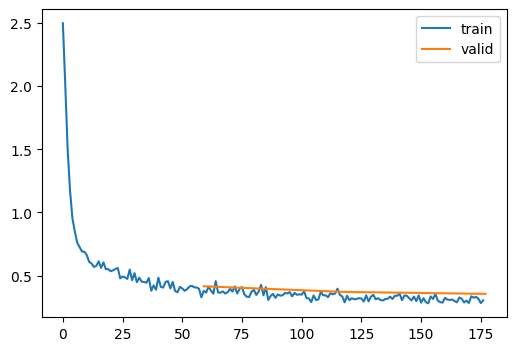

In [9]:
learn.fit(3)

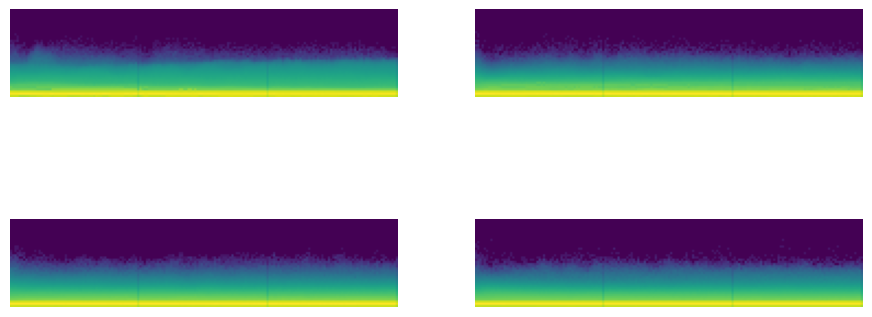

In [10]:
astats.color_dim()

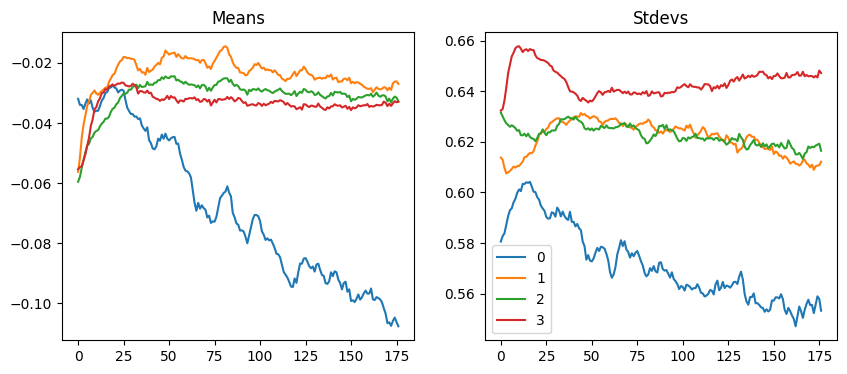

In [11]:
astats.plot_stats()

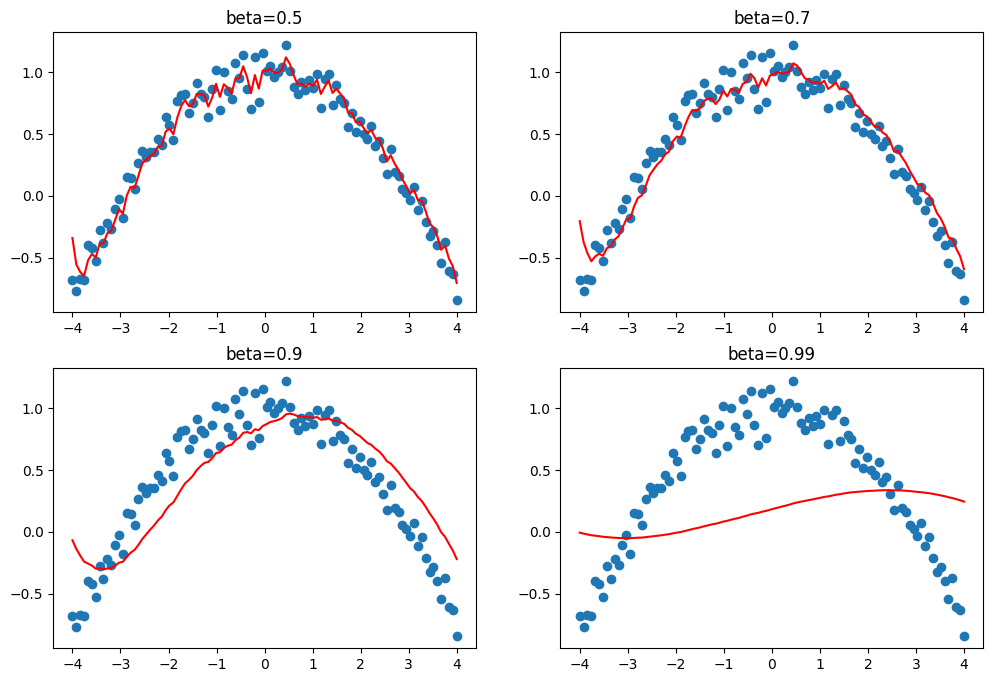

In [12]:
# proving and showing the concept
xs = torch.linspace(-4, 4, 100)
ys = 1 - (xs / 3) ** 2 + torch.randn(100) * 0.1
# Make the plots
_, axs = plt.subplots(2, 2, figsize=(12, 8))
betas = [0.5, 0.7, 0.9, 0.99]
for beta, ax in zip(betas, axs.flatten()):
    ax.scatter(xs, ys)
    avg, res = 0, []
    for yi in ys:
        avg = beta * avg + (1 - beta) * yi
        res.append(avg)
    ax.plot(xs, np.array(res), color='red');
    ax.set_title(f'beta={beta}')

here the 2 on the bottom are just extremely dependant on the weighted average which makes it worse , NOTE: (beta here if we plug it into lerp it is (1-beta) to get this result not beta)

# RMSProp

In [13]:
class RMSProp(SGD):
    def __init__(self,params,lr,wd=0.,sm=0.99,eps=1e-5): #sm = square momentum
        super().__init__(params,lr=lr,wd=wd)
        self.sm,self.eps = sm,eps
    def opt_step(self,p):
        if not hasattr(p,'sqr_avg'): p.sqr_avg = p.grad**2
        p.sqr_avg = p.sqr_avg.lerp_(p.grad**2, 1-self.sm)
        p -= (self.lr * p.grad) / (p.sqr_avg.sqrt() + self.eps)

accuracy,loss,epoch,train
0.766,0.664,0,train
0.823,0.482,0,eval
0.848,0.415,1,train
0.845,0.423,1,eval
0.866,0.367,2,train
0.850,0.402,2,eval


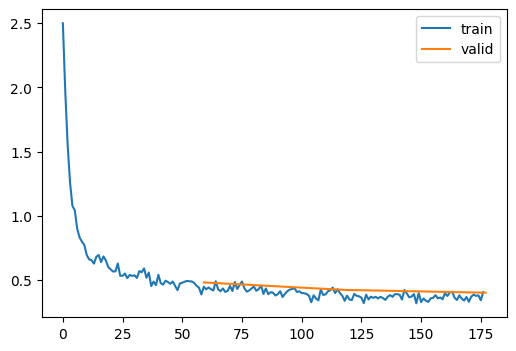

In [14]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=3e-3, cbs=cbs, opt_func=RMSProp)
learn.fit(3)

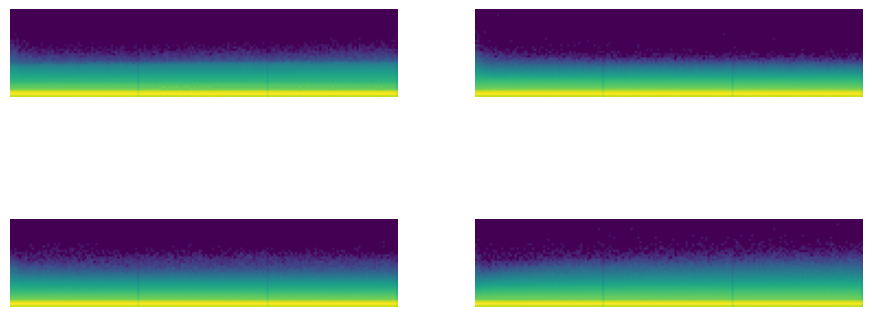

In [15]:
astats.color_dim()

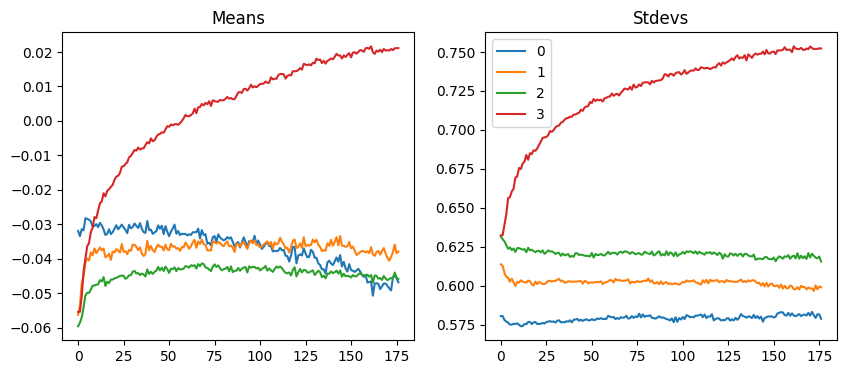

In [16]:
astats.plot_stats()

# Adam

In [17]:
class Adam(SGD):
    def __init__(self,params,lr,wd=0.,beta1=0.9,beta2=0.99,eps=1e-5):
        super().__init__(params,lr,wd)
        self.beta1,self.beta2,self.eps = beta1,beta2,eps
    def opt_step(self,p):
        if not hasattr(p,'avg'): p.avg = torch.zeros_like(p.grad.data)
        if not hasattr(p, 'sqr_avg'): p.sqr_avg = torch.zeros_like(p.grad.data)
        p.avg = p.avg.lerp_(p.grad, 1-self.beta1)
        p.sqr_avg = p.sqr_avg.lerp_(p.grad**2, 1-self.beta2)
        unbias_avg = p.avg / (1 - (self.beta1 ** (self.i+1)))
        unbias_sqr_avg = p.sqr_avg / (1 - (self.beta2 ** (self.i+1)))
        p  -= (self.lr * unbias_avg) / (unbias_sqr_avg + self.eps).sqrt()

    eps OUTSIDE:                    eps INSIDE:
    ─────────────────────────────   ─────────────────────────────
    sqrt(sqr_avg) + 1e-5            sqrt(sqr_avg + 1e-5)

    eps is in gradient scale        eps is in SQUARED scale
    1e-5 feels big here             1e-5 is tiny here
                                    sqrt shrinks it even further
                                    barely affects the result ✓

accuracy,loss,epoch,train
0.792,0.583,0,train
0.839,0.428,0,eval
0.870,0.359,1,train
0.857,0.381,1,eval
0.886,0.312,2,train
0.874,0.345,2,eval


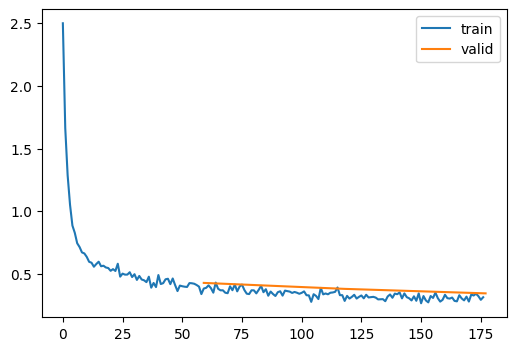

In [18]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=6e-3, cbs=cbs, opt_func=Adam)
learn.fit(3)

# Schedulers

In [19]:
(o for o in dir(lr_scheduler) if o[0].isupper() and o[1].islower())

<generator object <genexpr> at 0x70b7411bbed0>

In [20]:
# here we are just going to look at the different techniques that pytorch offers ( we skip the __dunder__ stuff and the stuff that aren't important
list((o for o in dir(lr_scheduler) if o[0].isupper() and o[1].islower()))

['Any',
 'Callable',
 'ChainedScheduler',
 'ConstantLR',
 'CosineAnnealingLR',
 'CosineAnnealingWarmRestarts',
 'Counter',
 'CyclicLR',
 'Dict',
 'ExponentialLR',
 'Iterable',
 'LambdaLR',
 'LinearLR',
 'List',
 'Literal',
 'MultiStepLR',
 'MultiplicativeLR',
 'OneCycleLR',
 'Optimizer',
 'Optional',
 'PolynomialLR',
 'ReduceLROnPlateau',
 'Sequence',
 'SequentialLR',
 'StepLR',
 'SupportsFloat',
 'Tensor',
 'TypedDict',
 'Union']

In [21]:
# same thing (diff syntax) and 'str' not 'list'
' | '.join(filter(lambda x: x[0].isupper() and x[1].islower(), dir(lr_scheduler)))

'Any | Callable | ChainedScheduler | ConstantLR | CosineAnnealingLR | CosineAnnealingWarmRestarts | Counter | CyclicLR | Dict | ExponentialLR | Iterable | LambdaLR | LinearLR | List | Literal | MultiStepLR | MultiplicativeLR | OneCycleLR | Optimizer | Optional | PolynomialLR | ReduceLROnPlateau | Sequence | SequentialLR | StepLR | SupportsFloat | Tensor | TypedDict | Union'

In [22]:
# make a learner and train for single batch
learn = TrainLearner(get_model(), dls, F.cross_entropy, lr=6e-3, cbs=[DeviceCB(), SingleBatchCB()])
learn.fit(1)

In [23]:
opt = learn.opt ; opt

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.006
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [24]:
dir(opt)

['OptimizerPostHook',
 'OptimizerPreHook',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_cuda_graph_capture_health_check',
 '_group_tensors_by_device_and_dtype',
 '_init_group',
 '_optimizer_load_state_dict_post_hooks',
 '_optimizer_load_state_dict_pre_hooks',
 '_optimizer_state_dict_post_hooks',
 '_optimizer_state_dict_pre_hooks',
 '_optimizer_step_code',
 '_optimizer_step_post_hooks',
 '_optimizer_step_pre_hooks',
 '_patch_step_function',
 '_process_value_according_to_param_policy',
 '_warned_capturable_if_run_uncaptured',
 '_zero_grad_profile_name',
 'add_param_group',
 'defaults',
 'load_state_dict',
 'param

In [25]:
# this shows the useful attr that opt has (removing the __dunder__ , private, ...)
list((o for o in dir(opt) if o[0]!='_'))

['OptimizerPostHook',
 'OptimizerPreHook',
 'add_param_group',
 'defaults',
 'load_state_dict',
 'param_groups',
 'profile_hook_step',
 'register_load_state_dict_post_hook',
 'register_load_state_dict_pre_hook',
 'register_state_dict_post_hook',
 'register_state_dict_pre_hook',
 'register_step_post_hook',
 'register_step_pre_hook',
 'state',
 'state_dict',
 'step',
 'zero_grad']

    # 3. USEFUL PUBLIC STUFF:
    opt.step()           # do one optimization step
    opt.zero_grad()      # clear gradients
    opt.state_dict()     # save optimizer state (for checkpointing)
    opt.load_state_dict()# load saved state
    opt.param_groups     # list of parameter groups with lr, wd etc
    opt.state            # dict of per-parameter state (avg, sqr_avg)
    opt.defaults         # default hyperparams (lr, betas, eps)
    opt.add_param_group()# add new group of parameters

    ## STORED AS DICTIONARIES ##

    # opt.state [params tensor]
    → {param_tensor: {'exp_avg': tensor, 'exp_avg_sq': tensor}}
    stores running averages PER PARAMETER ✅ , just as we made in our library but as
     'dic' not 'attr'(p.exp_avg)

    # opt.param_groups [group]
    → [{'params': [...], 'lr': 0.001, 'betas': (0.9,0.99)}]
    stores hyperparams for each group of parameters

In [26]:
param = next(iter(learn.model.parameters()))
param.shape , param

(torch.Size([8, 1, 3, 3]),
 Parameter containing:
 tensor([[[[ 0.15, -0.19,  0.08],
           [-0.01, -0.06,  0.26],
           [ 0.16, -0.30,  0.23]]],
 
 
         [[[ 0.05,  0.14,  0.03],
           [ 0.33,  0.18, -0.04],
           [-0.31,  0.18, -0.31]]],
 
 
         [[[ 0.18,  0.06,  0.13],
           [ 0.10, -0.25, -0.14],
           [-0.07, -0.31,  0.22]]],
 
 
         [[[-0.16, -0.16, -0.12],
           [ 0.18, -0.00,  0.15],
           [ 0.17, -0.01,  0.27]]],
 
 
         [[[ 0.16,  0.19,  0.33],
           [ 0.13,  0.27,  0.18],
           [-0.14,  0.01, -0.17]]],
 
 
         [[[ 0.26,  0.10, -0.23],
           [ 0.30,  0.19,  0.02],
           [-0.24, -0.16, -0.30]]],
 
 
         [[[-0.22,  0.32, -0.02],
           [ 0.29,  0.17,  0.30],
           [ 0.11, -0.19,  0.31]]],
 
 
         [[[-0.28,  0.09,  0.09],
           [ 0.22, -0.24,  0.12],
           [ 0.04, -0.24,  0.05]]]], device='cuda:0', requires_grad=True))

In [27]:
l = list(learn.model.parameters())
for params in l: print(params.shape)

torch.Size([8, 1, 3, 3])
torch.Size([8])
torch.Size([16, 8, 3, 3])
torch.Size([16])
torch.Size([32, 16, 3, 3])
torch.Size([32])
torch.Size([64, 32, 3, 3])
torch.Size([64])
torch.Size([10, 64, 3, 3])
torch.Size([10])


here we can see the conv weights , biases

In [28]:
state = opt.state[param] ; state

{}

    before training:    opt.state[param] = {}
    after 1 batch:      opt.state[param] = {'exp_avg': ...,
                                            'exp_avg_sq': ...,
                                            'step': 1}

In [29]:
len(opt.param_groups)

1

In [30]:
pg = opt.param_groups[0]
list(pg)

['params',
 'lr',
 'momentum',
 'dampening',
 'weight_decay',
 'nesterov',
 'maximize',
 'foreach',
 'differentiable',
 'fused']

In [31]:
# lets make a scheduler
sched = lr_scheduler.CosineAnnealingLR(opt, 100)

`Tmax` in` (opt,Tmax) `-> to adjust the length of the steps on the cosine curve so that it work properly

In [32]:
sched.base_lrs # default learner optimizer lr we made

[0.006]

In [33]:
sched.get_last_lr() # the last one

[0.006]

In [34]:
# ploting lr so that we can see what is happening
def sched_lrs(sched, steps):
    lrs = [sched.get_last_lr()]
    for i in range(steps):
        sched.optimizer.step()
        sched.step()
        lrs.append(sched.get_last_lr())
    plt.plot(lrs)

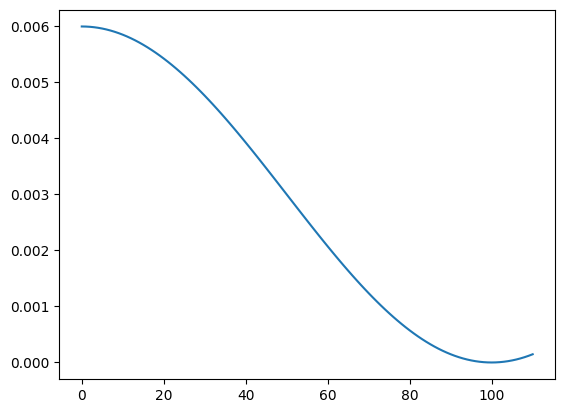

In [35]:
sched_lrs(sched, 110)

we made it here more than the  steps we made (100) by 10 and you can see it started increasing at the end

# Scheduler CBs

In [36]:
class BaseSchedCB(Callback):
    def __init__(self,sched): self.sched = sched
    def before_fit(self,learn): self.schedo = self.sched(learn.opt)
    def _step(self,learn):
        if learn.training : self.schedo.step()

In [37]:
class BatchSchedCB(BaseSchedCB):
    def after_batch(self,learn): self._step(learn)

In [38]:
class EpochSchedCB(BaseSchedCB):
    def after_epoch(self,learn): self._step(learn)

In [41]:
class RecorderCB(Callback):
    def __init__(self,**d): self.d = d
    def before_fit(self,learn):
        self.recs = {k:[] for k in self.d}
        self.pg = learn.opt.param_groups[0] # to get the current lr
    def after_batch(self,learn):
        if not learn.training : return
        for k,v in self.d.items():
            self.recs[k].append(v(self))
    def plot(self):
        for k,v in self.recs.items():
            plt.plot(v, label=k)
            plt.legend()
            plt.show()

In [42]:
def _lr(cb): return cb.pg['lr']

In [43]:
len(dls.train)

59

In [44]:
tmax = 3 * len(dls.train)
sched = partial(lr_scheduler.CosineAnnealingLR, T_max=tmax)

accuracy,loss,epoch,train
0.806,0.525,0,train
0.849,0.410,0,eval
0.878,0.331,1,train
0.879,0.328,1,eval
0.897,0.282,2,train
0.882,0.316,2,eval


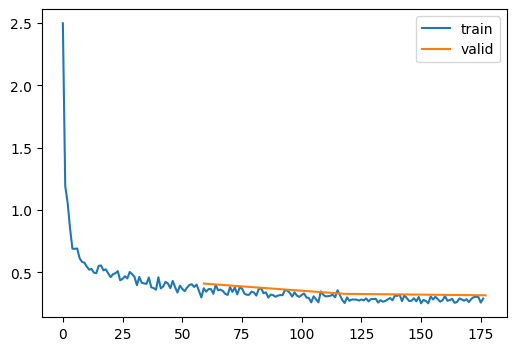

In [45]:
set_seed(42)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
rec = RecorderCB(lr=_lr)
xtra = [BatchSchedCB(sched),rec]
learn = TrainLearner(model, dls, F.cross_entropy, lr=2e-2, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(3)

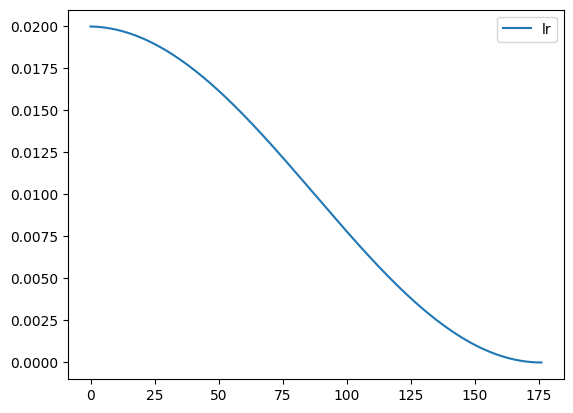

In [48]:
rec.plot()

accuracy,loss,epoch,train
0.807,0.523,0,train
0.855,0.383,0,eval
0.880,0.328,1,train
0.873,0.334,1,eval
0.899,0.275,2,train
0.884,0.309,2,eval


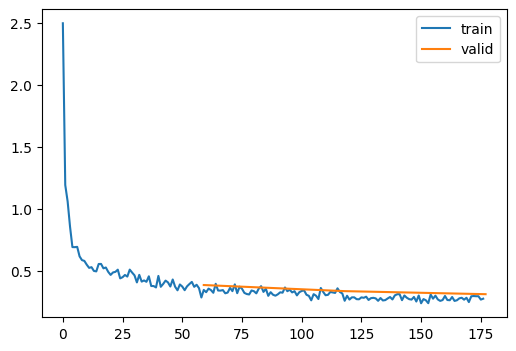

In [49]:
sched = partial(lr_scheduler.CosineAnnealingLR, T_max=3)
set_seed(42)
xtra = [EpochSchedCB(sched),rec]
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, F.cross_entropy, lr=2e-2, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(3)

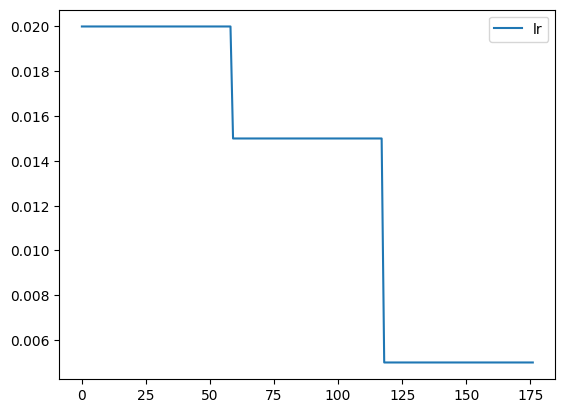

In [50]:
rec.plot()

# 1 Cycle training

    LESLIE SMITH discovered:
    ─────────────────────────────────────────
    instead of constant or decreasing lr
    try this specific pattern:

    lr:
    0.06│         /\
        │        /  \
        │       /    \
    0.006│     /      \________
        │     /
        └────────────────────── batches
        warmup  peak   cooldown

    3 phases:
    1. WARMUP:   lr goes UP   (model warms up safely)
    2. PEAK:     lr at max    (fast learning)
    3. COOLDOWN: lr goes DOWN (fine tune, very low at end)

In [51]:
def _beta1(cb): return cb.pg['betas'][0] # return the 1st beta
rec = RecorderCB(lr=_lr, mom=_beta1)

accuracy,loss,epoch,train
0.768,0.659,0,train
0.843,0.461,0,eval
0.857,0.389,1,train
0.860,0.387,1,eval
0.884,0.310,2,train
0.878,0.339,2,eval
0.906,0.253,3,train
0.896,0.285,3,eval
0.921,0.214,4,train
0.900,0.267,4,eval


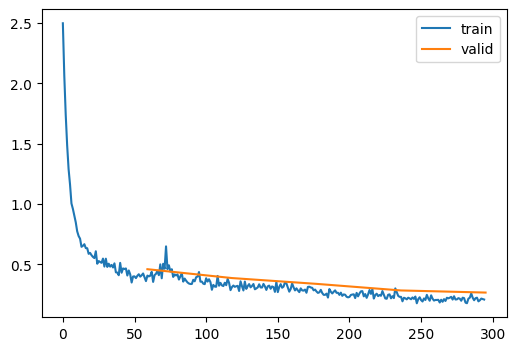

In [52]:
set_seed(42)
lr,epochs = 6e-2,5
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
xtra = [BatchSchedCB(sched), rec]
learn = TrainLearner(model, dls, F.cross_entropy, lr=lr, cbs=cbs+xtra, opt_func=optim.AdamW)
learn.fit(epochs)

    WHY pass lr_max that is at 1cycle in the learner?
    ─────────────────────────────────────────
    lr passed to TrainLearner = just a placeholder
    max_lr passed to OneCycleLR = the REAL lr ✓

    actual lr schedule:
    start:   lr/25    ← OneCycleLR sets this automatically
    peak:    max_lr   ← what you passed in
    end:     lr/1000  ← OneCycleLR sets this automatically

    optimizer NEEDS some initial lr to be created
    can't create optimizer with no lr
    but OneCycleLR overrides it immediately after first step ✓

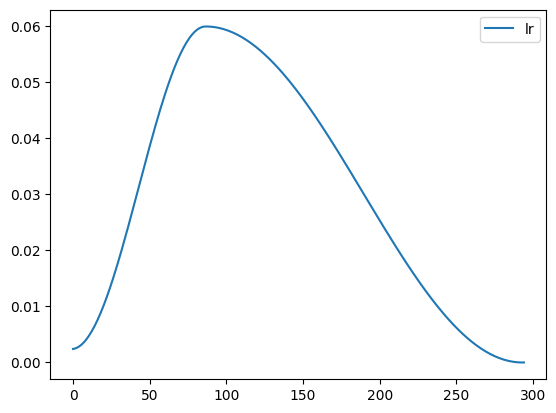

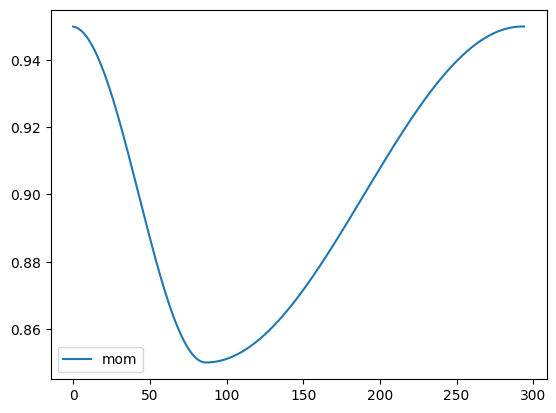

In [53]:
rec.plot()